### Import Library & Load Data

In [14]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_error,
    mean_absolute_percentage_error
)

X_train, X_test, y_train, y_test, scaler = joblib.load('../dataset/data_hasil_preprocessing.pkl')
print(f"Data berhasil dimuat! Training: {len(X_train)} | Testing: {len(X_test)}")

Data berhasil dimuat! Training: 6053 | Testing: 1514


### Fungsi Perhitungan 6 Metrik Evaluasi

In [16]:
def hitung_metrik_jurnal(y_aktual, y_prediksi, jumlah_fitur=7):
    n = len(y_aktual)
    r2   = r2_score(y_aktual, y_prediksi)
    mae  = mean_absolute_error(y_aktual, y_prediksi)
    mse  = mean_squared_error(y_aktual, y_prediksi)
    rmse = np.sqrt(mse)
    mape = mean_absolute_percentage_error(y_aktual, y_prediksi)
    adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - jumlah_fitur - 1))
    
    return {
        'R2': round(r2, 3),
        'Mean absolute error': round(mae, 3),
        'Mean squared error': round(mse, 3),
        'Root mean squared error': round(rmse, 3),
        'Mean absolute percentage error': round(mape, 3),
        'Adjusted R2': round(adj_r2, 3)
    }

### Pelatihan dan Pengujian Model XGBoost

In [17]:
# Inisialisasi model XGBoost Regressor dengan parameter standar artikel
model_xgb = XGBRegressor(
    reg_alpha=0,
    reg_lambda=1,
    random_state=42
)

# Melatih model pada Data Training dan menguji pada Data Testing
model_xgb.fit(X_train, y_train)

y_pred_train_xgb = model_xgb.predict(X_train)
y_pred_test_xgb  = model_xgb.predict(X_test)

metrik_train_xgb = hitung_metrik_jurnal(y_train, y_pred_train_xgb, jumlah_fitur=X_train.shape[1])
metrik_test_xgb  = hitung_metrik_jurnal(y_test, y_pred_test_xgb, jumlah_fitur=X_test.shape[1])

df_tabel_xgb = pd.DataFrame({
    f'Training ({len(X_train)})': metrik_train_xgb,
    f'Testing ({len(X_test)})': metrik_test_xgb
})

print("HASIL PREDIKSI MENGGUNAKAN XGBOOST REGRESSION:")
display(df_tabel_xgb)

HASIL PREDIKSI MENGGUNAKAN XGBOOST REGRESSION:


,Training (6053),Testing (1514)
R2,0.962,0.774
Mean absolute error,0.131,0.296
Mean squared error,0.038,0.234
Root mean squared error,0.194,0.484
Mean absolute percentage error,0.679,1.353
Adjusted R2,0.962,0.773


### Visualisasi Line Plot XGBoost

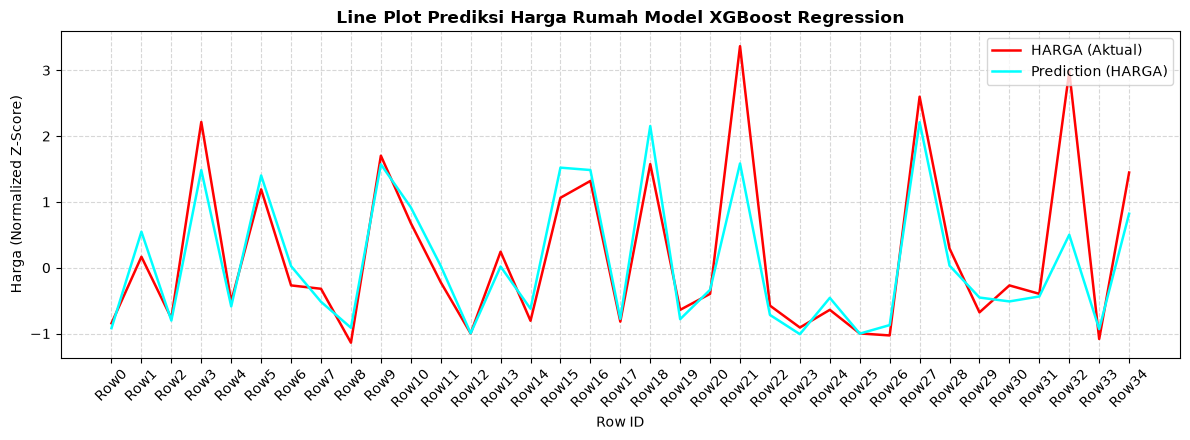

In [18]:
jumlah_plot = 35
x_labels = [f"Row{i}" for i in range(jumlah_plot)]

plt.figure(figsize=(12, 4.5))
plt.plot(x_labels, y_test.values[:jumlah_plot], color='red', linewidth=1.8, label='HARGA (Aktual)')
plt.plot(x_labels, y_pred_test_xgb[:jumlah_plot], color='cyan', linewidth=1.8, label='Prediction (HARGA)')

plt.title('Line Plot Prediksi Harga Rumah Model XGBoost Regression', fontweight='bold')
plt.xlabel('Row ID')
plt.ylabel('Harga (Normalized Z-Score)')
plt.xticks(rotation=45)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Menyimpan Hasil XGBoost

In [19]:
hasil_xgb = {
    'Model': 'XGBoost',
    'Training': metrik_train_xgb,
    'Testing': metrik_test_xgb,
    'y_test': y_test,
    'y_pred_test': y_pred_test_xgb
}

joblib.dump(hasil_xgb, 'hasil_xgb.pkl')
print("Hasil XGBoost Regression berhasil disimpan ke 'model/hasil_xgb.pkl'!")

Hasil XGBoost Regression berhasil disimpan ke 'model/hasil_xgb.pkl'!
